# Palmer Penguins | Flipper Length and Body Mass

Gerardo Oburu Ndong · November 23, 2026  
CIS215 Capstone 12.6

## Initial data exploration

I’m using the simplified Palmer Penguins CSV. The [data notes](../data/README.md) explain where it came from and who was sampled.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

%matplotlib inline

# I am going to support a kernel started at the project root or in notebooks/.
project_root = Path("..") if Path("../data/README.md").is_file() else Path(".")
data_path = project_root / "data" / "raw" / "penguins.csv"
if not data_path.is_file():
    raise FileNotFoundError("Open the notebook from the project root or notebooks folder.")

penguins_raw = pd.read_csv(data_path)
penguins_raw.info()
display(penguins_raw.describe(include="all").round(2))
display(penguins_raw.isna().sum().rename("missing_rows").to_frame())
print(f"Exact duplicate rows: {penguins_raw.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
count,344,344,342.00,342.00,342.00,342.00,333,344.00
unique,3,3,NaN,NaN,NaN,NaN,2,NaN
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,male,NaN
freq,152,168,NaN,NaN,NaN,NaN,168,NaN
mean,NaN,NaN,43.92,17.15,200.92,4201.75,NaN,2008.03
std,NaN,NaN,5.46,1.97,14.06,801.95,NaN,0.82
min,NaN,NaN,32.10,13.10,172.00,2700.00,NaN,2007.00
25%,NaN,NaN,39.22,15.60,190.00,3550.00,NaN,2007.00
50%,NaN,NaN,44.45,17.30,197.00,4050.00,NaN,2008.00
75%,NaN,NaN,48.50,18.70,213.00,4750.00,NaN,2009.00


,missing_rows
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


Exact duplicate rows: 0


The exploration output shows 344 rows and eight columns. Both bill columns, flipper length, and body mass each have two missing values. Recorded sex is missing in 11 rows. I found no exact duplicate rows. The simplified file has no bird ID, so that check only tells me whether entire rows match.

## Data cleaning and preparation

| Column | How I handled missing values |
|---|---|
| Species | No missing values. A row without a species could not go into a species comparison. |
| Island | No missing values. Island is used to check coverage. |
| Bill length | Two missing values. I left them blank because bill length does not enter my analysis. |
| Bill depth | Two missing values. I left them blank for the same reason. |
| Flipper length | Two missing values. I excluded those rows from the paired analysis because a missing flipper length cannot be plotted or correlated with mass. |
| Body mass | Two missing values, on the same rows as flipper length. I excluded those rows once and kept the original CSV intact. |
| Sex | Eleven missing values in the original file. I kept unknown sex in the pooled and species summaries when both measurements exist. I used known values for the sex comparison. |
| Year | No missing values. I kept the original year to describe the field seasons. |

I trimmed spaces in the group labels, standardized recorded sex to lowercase, and changed the display spelling of Adelie to Adélie. I checked for nonpositive dimensions and used kilograms on charts because the labels are easier to read.

In [2]:
cleaned = penguins_raw.copy()
for column in ["species", "island", "sex"]:
    cleaned[column] = cleaned[column].str.strip().replace("", pd.NA)
cleaned["sex"] = cleaned["sex"].str.lower()
cleaned["species"] = cleaned["species"].replace({"Adelie": "Adélie"})

measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
assert not cleaned[measurements].le(0).any().any(), "Check nonpositive measurements"
assert not cleaned[["species", "island", "year"]].isna().any().any()
assert not cleaned.duplicated().any(), "Review matching rows before proceeding"

paired = cleaned.dropna(subset=["flipper_length_mm", "body_mass_g"]).copy()
paired["body_mass_kg"] = paired["body_mass_g"] / 1000
print(f"Paired analysis: {len(paired)} of {len(cleaned)} rows")
print(f"Paired rows with unknown sex: {paired['sex'].isna().sum()}")

# Save the rows used in the plots and comparisons.
cleaned_path = project_root / "data" / "processed" / "penguins_paired.csv"
cleaned_path.parent.mkdir(parents=True, exist_ok=True)
paired.to_csv(cleaned_path, index=False)

Paired analysis: 342 of 344 rows
Paired rows with unknown sex: 9


## Analysis question

Among the penguins in this dataset, how closely does flipper length go with body mass, and how does that relationship change when I look at each species on its own?

In [3]:
# Pearson r measures the direction and strength of a linear relationship.
variables = ["flipper_length_mm", "body_mass_kg"]
display(paired[variables].describe().round(2))

overall_r = paired["flipper_length_mm"].corr(paired["body_mass_kg"])
species_groups = paired.groupby("species", sort=True)
species_summary = species_groups.agg(
    observations=("body_mass_kg", "size"),
    mean_flipper_mm=("flipper_length_mm", "mean"),
    mean_mass_kg=("body_mass_kg", "mean"),
)
species_summary["pearson_r"] = pd.Series({
    species: group["flipper_length_mm"].corr(group["body_mass_kg"])
    for species, group in species_groups
})
print(f"Pooled Pearson r: {overall_r:.3f}")
display(species_summary.round(3))

,flipper_length_mm,body_mass_kg
count,342.00,342.00
mean,200.92,4.20
std,14.06,0.80
min,172.00,2.70
25%,190.00,3.55
50%,197.00,4.05
75%,213.00,4.75
max,231.00,6.30


Pooled Pearson r: 0.871


,observations,mean_flipper_mm,mean_mass_kg,pearson_r
species,,,,
Adélie,151,189.954,3.701,0.468
Chinstrap,68,195.824,3.733,0.642
Gentoo,123,217.187,5.076,0.703


The pooled correlation is 0.87 across 342 measurements. The species results run from 0.47 for Adélie to 0.70 for Gentoo. Gentoo also had the longest average flippers (217.2 mm) and the highest average mass (5.08 kg). When I put all three species on one chart, that separation helps explain why the overall relationship looks stronger.

In [4]:
figure_dir = project_root / "output" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def save_and_show(figure, filename, dpi=300):
    """Save a figure in output/figures at the given resolution, then display it."""
    figure.savefig(figure_dir / filename, dpi=dpi, facecolor="white")
    plt.show()

colors = ["#27678e", "#9b5c18", "#28694f"]
markers = ["o", "^", "s"]

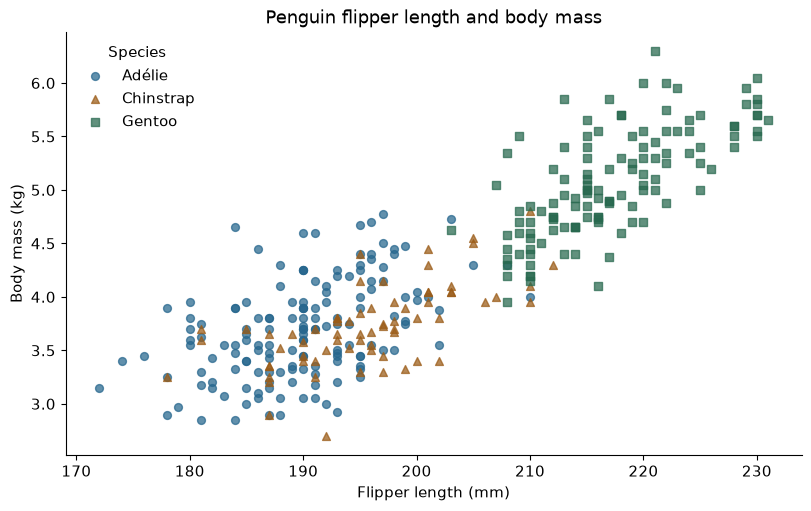

In [5]:
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
for (species, group), color, marker in zip(species_groups, colors, markers):
    ax.scatter(group["flipper_length_mm"], group["body_mass_kg"],
               label=species, color=color, marker=marker, alpha=0.73, s=32)
ax.set(title="Penguin flipper length and body mass",
       xlabel="Flipper length (mm)", ylabel="Body mass (kg)")
ax.legend(title="Species", frameon=False)
save_and_show(fig, "flipper_mass_scatter.png")

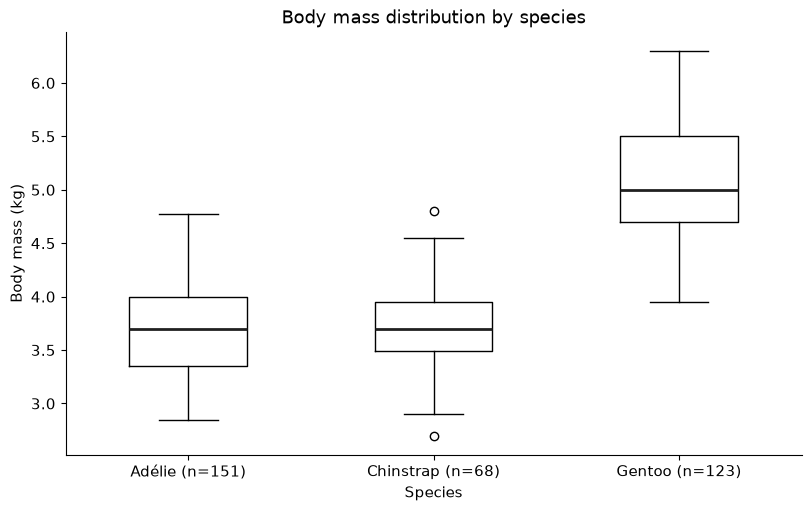

In [6]:
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
groups = [group["body_mass_kg"] for _, group in species_groups]
positions = range(1, len(groups) + 1)
ax.boxplot(groups, positions=positions, widths=0.48,
           medianprops={"color": "#202020", "linewidth": 2})
ax.set_xticks(list(positions), [f"{name} (n={len(group)})" for name, group in species_groups])
ax.set(title="Body mass distribution by species", xlabel="Species", ylabel="Body mass (kg)")
save_and_show(fig, "body_mass_by_species.png")

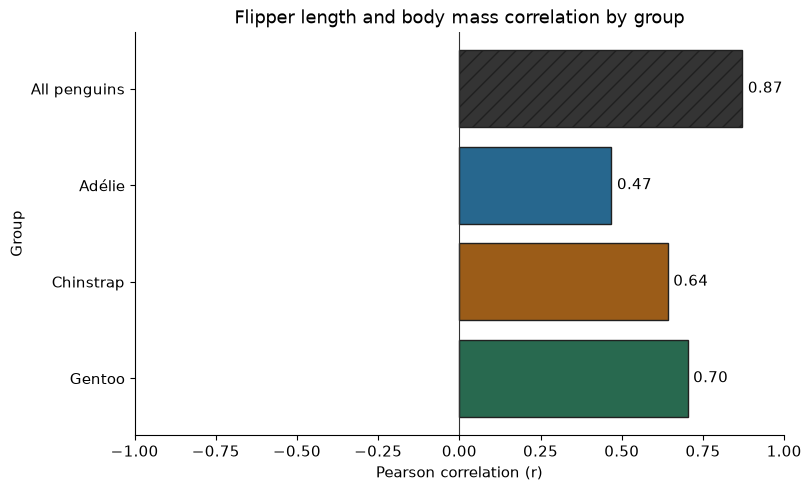

In [7]:
correlations = pd.concat([pd.Series({"All penguins": overall_r}), species_summary["pearson_r"]])
fig, ax = plt.subplots(figsize=(8, 4.8), layout="constrained")
bars = ax.barh(correlations.index, correlations, color=["#343434"] + colors, edgecolor="#202020")
bars[0].set_hatch("//")
ax.invert_yaxis()
ax.set(title="Flipper length and body mass correlation by group",
       xlabel="Pearson correlation (r)", ylabel="Group", xlim=(-1, 1))
ax.axvline(0, color="#333333", linewidth=0.8)
ax.bar_label(bars, fmt="%.2f", padding=4)
save_and_show(fig, "correlation_by_group.png")

## Sample coverage and recorded sex

In [8]:
display(pd.crosstab(cleaned["species"], cleaned["island"]))
display(pd.crosstab(cleaned["species"], cleaned["year"]))
display(pd.crosstab(cleaned["species"], cleaned["sex"].fillna("Unknown")))

known_sex = paired.dropna(subset=["sex"])
sex_summary = pd.DataFrame([
    {"species": species, "recorded_sex": sex, "observations": len(group),
     "mean_mass_kg": group["body_mass_kg"].mean(),
     "pearson_r": group["flipper_length_mm"].corr(group["body_mass_kg"])}
    for (species, sex), group in known_sex.groupby(["species", "sex"])
]).set_index(["species", "recorded_sex"])
display(sex_summary.round(3))

island,Biscoe,Dream,Torgersen
species,,,
Adélie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


year,2007,2008,2009
species,,,
Adélie,50,50,52
Chinstrap,26,18,24
Gentoo,34,46,44


sex,Unknown,female,male
species,,,
Adélie,6,73,73
Chinstrap,0,34,34
Gentoo,5,58,61


observations  mean_mass_kg  pearson_r
species   recorded_sex                                       
Adélie    female                  73         3.369      0.263
          male                    73         4.043      0.360
Chinstrap female                  34         3.527      0.242
          male                    34         3.939      0.665
Gentoo    female                  58         4.680      0.488
          male                    61         5.485      0.330

## Limitations and Bias Considerations

- **Collection.** The island table shows all 68 Chinstrap observations came from Dream and all 124 Gentoo observations came from Biscoe. Only Adélie appears on all three islands. The study covers adult foragers, so chicks and birds in other colonies are missing. The sampling design makes it hard to separate species patterns from site conditions.
- **Measurement.** The CSV gives dimensions in millimeters and mass in grams, but it has no observer or instrument fields. I cannot check whether measurement differences across field crews affected the relationship. Two rows lack the paired measurements. Nine usable pairs have unknown recorded sex, so the sex summaries describe 333 known-sex observations.
- **Historical coverage.** The data come from 2007–2009. There are only three field seasons here, so I cannot use them to describe today’s penguins or estimate a long-term trend.
- **Recorded sex.** In the subgroup table, Chinstrap correlation was about 0.24 for females and 0.66 for males, with 34 observations in each group. The male mean mass was higher within all three species. These sample comparisons can be influenced by group size, missing data, and collection conditions. I did not test whether the differences would hold in the broader population.

## Questions & Analysis

### Question 1

The island bias would be the easiest for me to miss if I only looked at the scatter plot. The **Sample coverage and recorded sex** table shows that all 68 Chinstrap observations came from Dream and all 124 Gentoo observations came from Biscoe. Someone could see Gentoo higher up on the plot and assume species explains the whole difference. With this sample, I can’t sort out how much the sites might matter. I think it’s my job to say where the data came from and who was left out so readers know how far they can take the results.

### Question 2

I’d start with the root README from **Add requirements.txt and verify relative paths**. It lists the Python version, install command, and notebook to open. The data README added in **Add initial data exploration** gives the exact CSV link. The **Initial data exploration** output gives my colleague a quick check: they should see 344 rows, and **Data cleaning and preparation** should leave 342 paired observations. They could still get stuck if Jupyter opens a kernel from a different Anaconda environment. I’d add a short Windows walkthrough showing how to register and select the right kernel. I’d also test the setup on a clean Windows machine.

## Project reflection

I learned how much one number can hide. I saw 0.87 in the pooled output, then saw that every species had a lower correlation on its own. The tricky part was deciding what to do with missing sex values. Keeping those rows in the main comparison gave me more usable measurements, and I could still check recorded sex separately. With more time, I’d look for more sites where the same species were measured. I’d like feedback on whether the charts make the pooled and species results easy to compare.

I used ChatGPT to help draft the notebook, document the cleaning choices, and set up the Git history. The reflection and analysis responses are drafts for me to check against my own experience.